In [1]:
%pip install requests beautifulsoup4 pandas numpy matplotlib seaborn lxml

   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB 487.6 kB/s eta 0:00:09
   - -------------------------------------- 0.1/4.0 MB 1.1 MB/s eta 0:00:04
   ----- ---------------------------------- 0.5/4.0 MB 3.0 MB/s eta 0:00:02
   ----------- ---------------------------- 1.1/4.0 MB 5.4 MB/s eta 0:00:01
   ------------------- -------------------- 1.9/4.0 MB 7.3 MB/s eta 0:00:01
   ----------------------- ---------------- 2.4/4.0 MB 7.5 MB/s eta 0:00:01
   -------------------------------- ------- 3.2/4.0 MB 9.4 MB/s eta 0:00:01
   ----------------------------------- ---- 3.6/4.0 MB 9.1 MB/s eta 0:00:01
   ------------------------------------- -- 3.8/4.0 MB 8.6 MB/s eta 0:00:01
   ---------------------------------------- 4.0/4.0 MB 8.2 MB/s eta 0:00:00
Note: you may need to restart t


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: C:\Users\Sri Dharma\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [2]:
import requests
import pandas as pd
import numpy as np
import re
import time
import matplotlib.pyplot as plt
import seaborn as sns

from bs4 import BeautifulSoup
from urllib.parse import urljoin
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

sns.set_theme(style="whitegrid", context="notebook")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
url = "https://www.bikewale.com/"

headers = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 Chrome/124.0 Safari/537.36"
    )
}

response = requests.get(url, headers=headers, timeout=20)

print("Status code:", response.status_code)
print("Page size:", len(response.text), "characters")

if response.status_code == 200:
    soup = BeautifulSoup(response.text, "html.parser")
    print("Website title:", soup.title.get_text(strip=True) if soup.title else "Not found")
else:
    print("Website request failed. Check access before proceeding.")

Status code: 200
Page size: 626770 characters
Website title: New Bikes, New Scooters, Electric Bikes - BikeWale


In [4]:
links = []

for a in soup.find_all("a", href=True):
    href = urljoin(url, a["href"])
    text = a.get_text(" ", strip=True)

    if "bikewale.com" in href and text:
        links.append({
            "Link_Text": text,
            "URL": href
        })

links_df = pd.DataFrame(links).drop_duplicates(subset="URL")

print("Unique links found:", len(links_df))
display(links_df.head(20))

Unique links found: 196


,Link_Text,URL
0,Yezdi Roadster,https://www.bikewale.com/yezdi-bikes/roadster/
1,TVS Apache RTR 160,https://www.bikewale.com/tvs-bikes/apache-160/
2,TVS Ronin,https://www.bikewale.com/tvs-bikes/ronin/
3,Bajaj Pulsar N160 2V,https://www.bikewale.com/bajaj-bikes/pulsar-n160/
4,TVS Raider 125,https://www.bikewale.com/tvs-bikes/raider-125/
5,Royal Enfield Hunter 350,https://www.bikewale.com/royalenfield-bikes/hunter-350/
6,Royal Enfield Classic 350,https://www.bikewale.com/royalenfield-bikes/classic-350/
7,Triumph New Tiger 1200,https://www.bikewale.com/triumph-bikes/new-tiger-1200/
8,Ducati Formula 73,https://www.bikewale.com/ducati-bikes/formula-73/
9,All Trending Bikes,https://www.bikewale.com/new-bikes-in-india/


In [5]:
# Keep only individual vehicle detail pages
bike_links = links_df[
    links_df["URL"].str.contains(
        r"bikewale\.com/[^/]+-bikes/[^/]+/?$",
        case=False,
        regex=True
    )
].copy()

# Remove duplicate URLs
bike_links = bike_links.drop_duplicates(subset="URL").reset_index(drop=True)

# Remove generic listing/navigation pages
exclude_names = [
    "all trending bikes",
    "new bikes in india",
    "popular bikes",
    "upcoming bikes"
]

bike_links = bike_links[
    ~bike_links["Link_Text"].str.lower().isin(exclude_names)
].reset_index(drop=True)

print("Individual bike links found:", len(bike_links))
display(bike_links.head(15))

Individual bike links found: 76


,Link_Text,URL
0,Yezdi Roadster,https://www.bikewale.com/yezdi-bikes/roadster/
1,TVS Apache RTR 160,https://www.bikewale.com/tvs-bikes/apache-160/
2,TVS Ronin,https://www.bikewale.com/tvs-bikes/ronin/
3,Bajaj Pulsar N160 2V,https://www.bikewale.com/bajaj-bikes/pulsar-n160/
4,TVS Raider 125,https://www.bikewale.com/tvs-bikes/raider-125/
5,Royal Enfield Hunter 350,https://www.bikewale.com/royalenfield-bikes/hunter-350/
6,Royal Enfield Classic 350,https://www.bikewale.com/royalenfield-bikes/classic-350/
7,Triumph New Tiger 1200,https://www.bikewale.com/triumph-bikes/new-tiger-1200/
8,Ducati Formula 73,https://www.bikewale.com/ducati-bikes/formula-73/
9,Royal Enfield Bullet 350,https://www.bikewale.com/royalenfield-bikes/bullet/


In [6]:
test_url = bike_links.loc[0, "URL"]

response = requests.get(
    test_url,
    headers=headers,
    timeout=20
)

print("Bike URL:", test_url)
print("Status code:", response.status_code)
print("HTML size:", len(response.text))

bike_soup = BeautifulSoup(response.text, "html.parser")

print(
    "Page title:",
    bike_soup.title.get_text(" ", strip=True)
    if bike_soup.title else "Not found"
)

# Inspect structured data, which may contain product specifications
json_ld = bike_soup.find_all(
    "script",
    type="application/ld+json"
)

print("JSON-LD blocks found:", len(json_ld))

for i, script in enumerate(json_ld[:3]):
    print(f"\n--- JSON-LD block {i + 1} ---")
    print(script.get_text()[:1500])

Bike URL: https://www.bikewale.com/yezdi-bikes/roadster/
Status code: 200
HTML size: 812955
Page title: Yezdi Roadster Price - Mileage, Images, Colours | BikeWale
JSON-LD blocks found: 3

--- JSON-LD block 1 ---
{"@type":"Product","url":"https://www.bikewale.com/yezdi-bikes/roadster/","description":"The Yezdi Roadster is a street bike available at a price range of Rs. 2,01,963 - Rs. 2,14,193 in India. It comes in 5 variants and 5 colours. It is powered by a 334 cc BS6 Phase 2B engine and has a  user reported mileage of 30 kmpl. With both front and rear disc brakes, the Yezdi Roadster comes with anti-locking braking system. The Roadster bike weighs 184 kg and has a fuel tank capacity of 12.5 liters. It develops a power output of 28.7 bhp and a torque of 30 Nm.","name":"Yezdi Roadster","image":[{"@type":"ImageObject","url":"https://imgd.aeplcdn.com/1280x720/n/cw/ec/1/versions/--smoke-grey1754999662468.jpg","width":"1280","height":"720"},{"@type":"ImageObject","url":"https://imgd.aeplcdn.

In [7]:
import json
import re
import time
import pandas as pd
import numpy as np
import requests
from bs4 import BeautifulSoup

def parse_number(pattern, text):
    match = re.search(pattern, text, flags=re.I)
    return float(match.group(1)) if match else np.nan

def extract_product_data(url, headers):
    response = requests.get(url, headers=headers, timeout=25)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")
    products = []

    for script in soup.find_all("script", type="application/ld+json"):
        try:
            data = json.loads(script.string or script.get_text())
        except (json.JSONDecodeError, TypeError):
            continue

        # JSON-LD may contain a single object or a list of objects.
        items = data if isinstance(data, list) else [data]

        for item in items:
            if not isinstance(item, dict):
                continue

            if item.get("@type") == "Product":
                products.append(item)

            # Also inspect nested graph objects.
            graph = item.get("@graph", [])
            if isinstance(graph, list):
                products.extend(
                    x for x in graph
                    if isinstance(x, dict) and x.get("@type") == "Product"
                )

    if not products:
        return None

    product = products[0]
    name = product.get("name", "")
    description = product.get("description", "")

    # Extract values from the product description.
    engine = parse_number(r"(\d+(?:\.\d+)?)\s*cc\b", description)
    mileage = parse_number(
        r"(?:user reported mileage|mileage)[^\d]{0,30}(\d+(?:\.\d+)?)\s*kmpl",
        description
    )
    power = parse_number(r"(\d+(?:\.\d+)?)\s*bhp\b", description)
    weight = parse_number(r"weighs\s+(\d+(?:\.\d+)?)\s*kg\b", description)

    # Use the lowest listed price from a range, if present.
    price_match = re.search(
        r"price range of Rs\.?\s*([\d,]+)(?:\s*-\s*Rs\.?\s*([\d,]+))?",
        description,
        flags=re.I
    )
    price = (
        float(price_match.group(1).replace(",", ""))
        if price_match else np.nan
    )

    return {
        "Bike_Name": name,
        "Price_INR": price,
        "Engine_CC": engine,
        "Mileage_KMPL": mileage,
        "Power_BHP": power,
        "Weight_KG": weight,
        "Description": description,
        "URL": url
    }


# Test on the first 10 bike URLs
test_records = []

for _, row in bike_links.head(10).iterrows():
    try:
        record = extract_product_data(row["URL"], headers)
        if record:
            test_records.append(record)
        else:
            print("No Product JSON-LD found:", row["Link_Text"])
    except Exception as e:
        print("Failed:", row["Link_Text"], "-", str(e))

    time.sleep(1)

test_df = pd.DataFrame(test_records)

print("Successfully extracted product records:", len(test_df))
display(
    test_df[
        ["Bike_Name", "Price_INR", "Engine_CC",
         "Mileage_KMPL", "Power_BHP", "Weight_KG"]
    ]
)

No Product JSON-LD found: Royal Enfield Classic 350
Successfully extracted product records: 9


,Bike_Name,Price_INR,Engine_CC,Mileage_KMPL,Power_BHP,Weight_KG
0,Yezdi Roadster,201963.0,334.00,30.00,28.70,184.0
1,TVS Apache RTR 160,110524.0,159.70,61.00,15.82,137.0
2,TVS Ronin,130809.0,225.90,41.00,20.10,159.0
3,Bajaj Pulsar N160 2V,122945.0,164.82,51.60,15.68,148.0
4,TVS Raider 125,86937.0,124.80,56.00,11.20,123.0
5,Royal Enfield Hunter 350,137640.0,349.34,36.22,20.20,181.0
6,Triumph New Tiger 1200,2099000.0,1160.00,NaN,155.80,250.0
7,Ducati Formula 73,NaN,NaN,NaN,74.01,NaN
8,Royal Enfield Bullet 350,166981.0,349.00,35.00,20.20,195.0


In [8]:
def extract_product_data(url, headers):
    response = requests.get(url, headers=headers, timeout=25)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    products = []

    def collect_products(obj):
        if isinstance(obj, dict):
            types = obj.get("@type", [])
            if isinstance(types, str):
                types = [types]

            if "Product" in types:
                products.append(obj)

            for value in obj.values():
                collect_products(value)

        elif isinstance(obj, list):
            for value in obj:
                collect_products(value)

    for script in soup.find_all("script", type="application/ld+json"):
        try:
            collect_products(json.loads(script.string or script.get_text()))
        except (json.JSONDecodeError, TypeError):
            continue

    product = products[0] if products else {}
    name = product.get("name", "")
    description = product.get("description", "")
    page_text = soup.get_text(" ", strip=True)

    # Use page text only as a fallback, not as proof that a value is correct.
    text = description if description else page_text

    def num(pattern, source=text):
        match = re.search(pattern, source, flags=re.I)
        return float(match.group(1).replace(",", "")) if match else np.nan

    # Prefer the product description for each field; fall back to page text.
    def get_num(pattern):
        value = num(pattern, description) if description else np.nan
        return value if pd.notna(value) else num(pattern, page_text)

    # Price: use the first/starting price in a stated range.
    price = get_num(
        r"(?:price range of|starting price of|starts at|ex-showroom price of)"
        r"\s*(?:Rs\.?|₹)?\s*([\d,]+)"
    )

    # Fallback for pages that state a price without those exact phrases.
    if pd.isna(price):
        price = num(r"₹\s*([\d,]+)", page_text)

    engine = get_num(r"(\d+(?:\.\d+)?)\s*cc\b")
    mileage = get_num(
        r"(?:user reported mileage|mileage)[^\d]{0,50}"
        r"(\d+(?:\.\d+)?)\s*kmpl"
    )
    power = get_num(r"(\d+(?:\.\d+)?)\s*bhp\b")
    weight = get_num(r"weighs\s+(\d+(?:\.\d+)?)\s*kg\b")

    if not name:
        h1 = soup.find("h1")
        name = h1.get_text(" ", strip=True) if h1 else ""

    return {
        "Bike_Name": name,
        "Price_INR": price,
        "Engine_CC": engine,
        "Mileage_KMPL": mileage,
        "Power_BHP": power,
        "Weight_KG": weight,
        "Description": description,
        "URL": url,
        "Has_Product_JSONLD": bool(products),
        "HTTP_Status": response.status_code
    }

In [9]:
all_records = []
errors = []

for i, row in bike_links.iterrows():
    bike_url = row["URL"]

    try:
        record = extract_product_data(bike_url, headers)

        if not record["Bike_Name"]:
            record["Bike_Name"] = row["Link_Text"]

        all_records.append(record)

        print(
            f"{i + 1}/{len(bike_links)} | "
            f"{record['Bike_Name']} | "
            f"Price: {record['Price_INR']} | "
            f"Engine: {record['Engine_CC']}"
        )

    except Exception as e:
        errors.append({
            "URL": bike_url,
            "Error": str(e)
        })
        print(f"{i + 1}/{len(bike_links)} FAILED: {bike_url} - {e}")

    time.sleep(1.2)

raw_df = pd.DataFrame(all_records)

print("\nTotal records scraped:", len(raw_df))
print("Failed requests:", len(errors))

display(raw_df.head(10))

raw_df.to_csv("bikewale_raw_dataset.csv", index=False)
pd.DataFrame(errors).to_csv("bikewale_scraping_errors.csv", index=False)

print("Raw dataset saved to bikewale_raw_dataset.csv")

1/76 | Yezdi Roadster | Price: 201963.0 | Engine: 334.0
2/76 | TVS Apache RTR 160 | Price: 110524.0 | Engine: 159.7
3/76 | TVS Ronin | Price: 130809.0 | Engine: 225.9
4/76 | Bajaj Pulsar N160 2V | Price: 122945.0 | Engine: 164.82
5/76 | TVS Raider 125 | Price: 86937.0 | Engine: 124.8
6/76 | Royal Enfield Hunter 350 | Price: 137640.0 | Engine: 349.34
7/76 | Jawa All Stars 42 | Price: 188934.0 | Engine: 349.0
8/76 | Triumph New Tiger 1200 | Price: 2099000.0 | Engine: 1160.0
9/76 | Ducati Formula 73 | Price: 2000000.0 | Engine: 803.0
10/76 | Royal Enfield Bullet 350 | Price: 166981.0 | Engine: 349.0
11/76 | Honda SP 125 | Price: 91370.0 | Engine: 123.94
12/76 | TVS iQube | Price: 119444.0 | Engine: nan
13/76 | Hero Xtreme 125R | Price: 92854.0 | Engine: 124.7
14/76 | Bajaj Pulsar NS200 | Price: 139260.0 | Engine: 199.5
15/76 | Yamaha MT 15 V2 | Price: 166586.0 | Engine: 155.0
16/76 | Bajaj Pulsar NS400Z | Price: 191359.0 | Engine: 349.13
17/76 | Jawa All Stars 42 Bobber | Price: 211010.0 

,Bike_Name,Price_INR,Engine_CC,Mileage_KMPL,Power_BHP,Weight_KG,Description,URL,Has_Product_JSONLD,HTTP_Status
0,Yezdi Roadster,201963.0,334.00,30.00,28.70,184.0,"The Yezdi Roadster is a street bike available at a price range of Rs. 2,01,963 - Rs. 2,14,193 in...",https://www.bikewale.com/yezdi-bikes/roadster/,True,200
1,TVS Apache RTR 160,110524.0,159.70,61.00,15.82,137.0,"The TVS Apache RTR 160 is a street bike available at a price range of Rs. 1,10,524 - Rs. 1,28,68...",https://www.bikewale.com/tvs-bikes/apache-160/,True,200
2,TVS Ronin,130809.0,225.90,41.00,20.10,159.0,"The TVS Ronin is a cruiser bike available at a price range of Rs. 1,30,809 - Rs. 1,64,207 in Ind...",https://www.bikewale.com/tvs-bikes/ronin/,True,200
3,Bajaj Pulsar N160 2V,122945.0,164.82,51.60,15.68,148.0,"The Bajaj Pulsar N160 2V is a street bike available at a price range of Rs. 1,22,945 - Rs. 1,32,...",https://www.bikewale.com/bajaj-bikes/pulsar-n160/,True,200
4,TVS Raider 125,86937.0,124.80,56.00,11.20,123.0,"The TVS Raider 125 is a commuter bike available at a price range of Rs. 86,937 - Rs. 1,03,398 in...",https://www.bikewale.com/tvs-bikes/raider-125/,True,200
5,Royal Enfield Hunter 350,137640.0,349.34,36.22,20.20,181.0,"The Royal Enfield Hunter 350 is a street bike available at a price range of Rs. 1,37,640 - Rs. 1...",https://www.bikewale.com/royalenfield-bikes/hunter-350/,True,200
6,Jawa All Stars 42,188934.0,349.00,35.00,20.20,195.0,,https://www.bikewale.com/royalenfield-bikes/classic-350/,True,200
7,Triumph New Tiger 1200,2099000.0,1160.00,NaN,155.80,250.0,"The Triumph New Tiger 1200 is a adventure bike available at a price range of Rs. 20,99,000 - Rs....",https://www.bikewale.com/triumph-bikes/new-tiger-1200/,True,200
8,Ducati Formula 73,2000000.0,803.00,NaN,74.01,NaN,"The Ducati Formula 73 is a cafe racer bike available at a starting price of Rs. 20,00,000 in Ind...",https://www.bikewale.com/ducati-bikes/formula-73/,True,200
9,Royal Enfield Bullet 350,166981.0,349.00,35.00,20.20,195.0,"The Royal Enfield Bullet 350 is a street bike available at a price range of Rs. 1,66,981 - Rs. 2...",https://www.bikewale.com/royalenfield-bikes/bullet/,True,200


Raw dataset saved to bikewale_raw_dataset.csv


In [10]:
feature_cols = [
    "Price_INR",
    "Engine_CC",
    "Mileage_KMPL",
    "Power_BHP",
    "Weight_KG"
]

print("Dataset shape:", raw_df.shape)
print("\nMissing values:")
display(raw_df[feature_cols].isna().sum().to_frame("Missing_Count"))

print("\nMissing percentage:")
display(
    (raw_df[feature_cols].isna().mean() * 100)
    .round(2)
    .to_frame("Missing_Percentage")
)

print("\nDuplicate bike names:", raw_df["Bike_Name"].duplicated().sum())

display(
    raw_df[
        raw_df["Price_INR"].isna() |
        raw_df["Engine_CC"].isna()
    ][["Bike_Name", "Price_INR", "Engine_CC", "URL"]]
)

Dataset shape: (76, 10)

Missing values:


,Missing_Count
Price_INR,0
Engine_CC,12
Mileage_KMPL,24
Power_BHP,12
Weight_KG,31



Missing percentage:


,Missing_Percentage
Price_INR,0.00
Engine_CC,15.79
Mileage_KMPL,31.58
Power_BHP,15.79
Weight_KG,40.79



Duplicate bike names: 0


,Bike_Name,Price_INR,Engine_CC,URL
11,TVS iQube,119444.0,NaN,https://www.bikewale.com/tvs-bikes/iqube/
18,Bajaj Chetak,120236.0,NaN,https://www.bikewale.com/bajaj-bikes/chetak/
19,Ather Konarc,101209.0,NaN,https://www.bikewale.com/ather-bikes/konarc/
20,TVS Orbiter,102431.0,NaN,https://www.bikewale.com/tvs-bikes/orbiter/
21,Ather Rizta,121178.0,NaN,https://www.bikewale.com/ather-bikes/rizta/
22,VIDA VX2,109936.0,NaN,https://www.bikewale.com/vida-bikes/vx2/
28,Honda Rebel 500 e-Clutch,650000.0,NaN,https://www.bikewale.com/honda-bikes/rebel-500-e-clutch/
29,Honda Rebel 500,540000.0,NaN,https://www.bikewale.com/honda-bikes/rebel-500/
35,BMW F 450 R,450000.0,NaN,https://www.bikewale.com/bmw-bikes/f-450-r/
36,Ampere Magnus G Max,102999.0,NaN,https://www.bikewale.com/ampere-bikes/magnus-g-max/


In [11]:
# Work on a copy of the scraped dataset
clean_df = raw_df.copy()

# 1. Remove comparison pages based on their URL
clean_df = clean_df[
    ~clean_df["URL"].str.contains("/compare-bikes/", case=False, na=False)
].copy()

# 2. Remove rows with comparison names
clean_df = clean_df[
    ~clean_df["Bike_Name"].str.contains(r"\s+vs\s+", case=False, na=False)
].copy()

# 3. Remove invalid or impossible prices
clean_df["Price_INR"] = pd.to_numeric(
    clean_df["Price_INR"], errors="coerce"
)

clean_df = clean_df[
    clean_df["Price_INR"].between(10000, 10000000)
].copy()

# 4. Remove duplicate URLs and names
clean_df = clean_df.drop_duplicates(subset="URL")
clean_df = clean_df.drop_duplicates(subset="Bike_Name")

clean_df = clean_df.reset_index(drop=True)

print("Original records:", len(raw_df))
print("Records after basic filtering:", len(clean_df))
print("Remaining comparison pages:",
      clean_df["URL"].str.contains("/compare-bikes/", na=False).sum())
print("Invalid prices:",
      (~clean_df["Price_INR"].between(10000, 10000000)).sum())

display(
    clean_df[
        ["Bike_Name", "Price_INR", "Engine_CC", "URL"]
    ].head(15)
)

Original records: 76
Records after basic filtering: 66
Remaining comparison pages: 0
Invalid prices: 0


,Bike_Name,Price_INR,Engine_CC,URL
0,Yezdi Roadster,201963.0,334.00,https://www.bikewale.com/yezdi-bikes/roadster/
1,TVS Apache RTR 160,110524.0,159.70,https://www.bikewale.com/tvs-bikes/apache-160/
2,TVS Ronin,130809.0,225.90,https://www.bikewale.com/tvs-bikes/ronin/
3,Bajaj Pulsar N160 2V,122945.0,164.82,https://www.bikewale.com/bajaj-bikes/pulsar-n160/
4,TVS Raider 125,86937.0,124.80,https://www.bikewale.com/tvs-bikes/raider-125/
5,Royal Enfield Hunter 350,137640.0,349.34,https://www.bikewale.com/royalenfield-bikes/hunter-350/
6,Jawa All Stars 42,188934.0,349.00,https://www.bikewale.com/royalenfield-bikes/classic-350/
7,Triumph New Tiger 1200,2099000.0,1160.00,https://www.bikewale.com/triumph-bikes/new-tiger-1200/
8,Ducati Formula 73,2000000.0,803.00,https://www.bikewale.com/ducati-bikes/formula-73/
9,Royal Enfield Bullet 350,166981.0,349.00,https://www.bikewale.com/royalenfield-bikes/bullet/


In [12]:
numeric_cols = [
    "Price_INR",
    "Engine_CC",
    "Mileage_KMPL",
    "Power_BHP",
    "Weight_KG"
]

for col in numeric_cols:
    clean_df[col] = pd.to_numeric(clean_df[col], errors="coerce")

# Flag suspicious values for manual review
clean_df["Review_Flag"] = ""

clean_df.loc[
    clean_df["Engine_CC"].notna() &
    ~clean_df["Engine_CC"].between(30, 2500),
    "Review_Flag"
] = "Check engine capacity"

clean_df.loc[
    clean_df["Mileage_KMPL"].notna() &
    ~clean_df["Mileage_KMPL"].between(1, 200),
    "Review_Flag"
] = "Check mileage"

clean_df.loc[
    clean_df["Power_BHP"].notna() &
    ~clean_df["Power_BHP"].between(0, 400),
    "Review_Flag"
] = "Check power"

print("Rows requiring review:")
display(
    clean_df.loc[
        clean_df["Review_Flag"] != "",
        ["Bike_Name", "Price_INR", "Engine_CC",
         "Mileage_KMPL", "Power_BHP", "Review_Flag", "URL"]
    ]
)

print("\nMissing-value counts:")
display(clean_df[numeric_cols].isna().sum().to_frame("Missing_Count"))

Rows requiring review:


,Bike_Name,Price_INR,Engine_CC,Mileage_KMPL,Power_BHP,Review_Flag,URL



Missing-value counts:


,Missing_Count
Price_INR,0
Engine_CC,10
Mileage_KMPL,22
Power_BHP,10
Weight_KG,22


In [13]:
def extract_brand(name):
    name = str(name).strip()

    known_brands = [
        "Royal Enfield", "Harley-Davidson", "Hero MotoCorp",
        "TVS", "Bajaj", "Honda", "Yamaha", "Suzuki",
        "KTM", "BMW", "Ducati", "Triumph", "Kawasaki",
        "Jawa", "Yezdi", "Ather", "OLA", "Ampere",
        "VIDA", "Aprilia", "River", "Ultraviolette"
    ]

    for brand in sorted(known_brands, key=len, reverse=True):
        if name.lower().startswith(brand.lower()):
            return brand

    return name.split()[0] if name else "Unknown"


clean_df["Brand"] = clean_df["Bike_Name"].apply(extract_brand)

print("Unique models:", clean_df["Bike_Name"].nunique())
print("Unique brands:", clean_df["Brand"].nunique())

display(clean_df["Brand"].value_counts().to_frame("Model_Count"))

Unique models: 66
Unique brands: 22


,Model_Count
Brand,
TVS,11
Bajaj,8
Hero,8
Royal Enfield,6
Honda,5
Jawa,3
Triumph,3
Yamaha,3
Ather,3


In [14]:
# Step 14: Identify suspicious records for verification

check_df = clean_df.copy()

# Check whether the bike name appears consistent with its URL
check_df["URL_Model"] = (
    check_df["URL"]
    .str.rstrip("/")
    .str.split("/")
    .str[-1]
)

# Display electric models that should not have petrol-engine CC
electric_keywords = [
    "iqube", "chetak", "konarc", "orbiter", "rizta",
    "vida", "vx2", "ather", "ola s1", "river indie",
    "magnus", "x-47"
]

check_df["Likely_EV"] = check_df["Bike_Name"].str.lower().apply(
    lambda name: any(keyword in name for keyword in electric_keywords)
)

print("Potential electric-bike records with engine CC:")
display(
    check_df[
        check_df["Likely_EV"] & check_df["Engine_CC"].notna()
    ][["Bike_Name", "Engine_CC", "URL"]]
)

print("\nRecords to verify: names, URLs, and suspicious specifications")
display(
    check_df[
        check_df["Likely_EV"] |
        check_df["Review_Flag"].ne("") |
        check_df["Bike_Name"].str.contains(
            "All Stars|Yamaha R2|Himalayan 750|Continental GT 750",
            case=False, na=False
        )
    ][
        ["Bike_Name", "Price_INR", "Engine_CC",
         "Mileage_KMPL", "Power_BHP", "URL"]
    ]
)

Potential electric-bike records with engine CC:


,Bike_Name,Engine_CC,URL
23,Ultraviolette X-47 Venom,501.0,https://www.bikewale.com/ultraviolette-bikes/x-47-venom/
24,OLA S1 X,124.6,https://www.bikewale.com/ola-bikes/s1-x/
25,Ather 450X,149.5,https://www.bikewale.com/ather-bikes/450x/
26,River Indie,149.5,https://www.bikewale.com/river-bikes/indie/



Records to verify: names, URLs, and suspicious specifications


,Bike_Name,Price_INR,Engine_CC,Mileage_KMPL,Power_BHP,URL
6,Jawa All Stars 42,188934.0,349.0,35.0,20.20,https://www.bikewale.com/royalenfield-bikes/classic-350/
11,TVS iQube,119444.0,NaN,NaN,NaN,https://www.bikewale.com/tvs-bikes/iqube/
16,Jawa All Stars 42 Bobber,211010.0,334.0,30.0,29.51,https://www.bikewale.com/jawa-bikes/42-bobber/
18,Bajaj Chetak,120236.0,NaN,NaN,NaN,https://www.bikewale.com/bajaj-bikes/chetak/
19,Ather Konarc,101209.0,NaN,NaN,NaN,https://www.bikewale.com/ather-bikes/konarc/
20,TVS Orbiter,102431.0,NaN,NaN,NaN,https://www.bikewale.com/tvs-bikes/orbiter/
21,Ather Rizta,121178.0,NaN,NaN,NaN,https://www.bikewale.com/ather-bikes/rizta/
22,VIDA VX2,109936.0,NaN,NaN,NaN,https://www.bikewale.com/vida-bikes/vx2/
23,Ultraviolette X-47 Venom,265000.0,501.0,NaN,40.00,https://www.bikewale.com/ultraviolette-bikes/x-47-venom/
24,OLA S1 X,89999.0,124.6,NaN,9.80,https://www.bikewale.com/ola-bikes/s1-x/


In [15]:
# Step 15: Correct known extraction errors

# 1. Remove the row with a clear bike-name/URL mismatch.
clean_df = clean_df[
    ~clean_df["URL"].str.contains(
        "/royalenfield-bikes/classic-350/",
        case=False,
        na=False
    )
].copy()

# 2. Mark electric bikes so petrol-engine specifications
# are not incorrectly interpreted as applicable.
electric_models = [
    "TVS iQube",
    "Bajaj Chetak",
    "Ather Konarc",
    "TVS Orbiter",
    "Ather Rizta",
    "VIDA VX2",
    "Ultraviolette X-47 Venom",
    "OLA S1 X",
    "Ather 450X",
    "River Indie",
    "Ampere Magnus G Max"
]

clean_df["Bike_Type"] = "Petrol/Other"

clean_df.loc[
    clean_df["Bike_Name"].isin(electric_models),
    "Bike_Type"
] = "Electric"

# 3. Engine CC is not applicable to electric bikes.
# Clear the false-positive values instead of replacing them with zero.
clean_df.loc[
    clean_df["Bike_Type"] == "Electric",
    "Engine_CC"
] = np.nan

# 4. Flag questionable records for source verification.
verification_keywords = [
    "Himalayan 750",
    "Continental GT 750",
    "Yamaha R2",
    "X-47 Venom"
]

clean_df["Verification_Status"] = "Needs source verification"

clean_df.loc[
    clean_df["Bike_Name"].str.contains(
        "|".join(verification_keywords),
        case=False,
        na=False
    ),
    "Verification_Status"
] = "Verify model and specifications"

# Review the updated data
print("Records remaining:", len(clean_df))
print("\nBike type counts:")
display(clean_df["Bike_Type"].value_counts().to_frame("Count"))

print("\nRecords requiring verification:")
display(
    clean_df[
        clean_df["Verification_Status"]
        == "Verify model and specifications"
    ][["Bike_Name", "Price_INR", "Engine_CC", "URL"]]
)

print("\nUpdated missing values:")
display(clean_df.isnull().sum().to_frame("Missing_Count"))

Records remaining: 65

Bike type counts:


,Count
Bike_Type,
Petrol/Other,54
Electric,11



Records requiring verification:


,Bike_Name,Price_INR,Engine_CC,URL
23,Ultraviolette X-47 Venom,265000.0,NaN,https://www.bikewale.com/ultraviolette-bikes/x-47-venom/
30,Royal Enfield Himalayan 750,400000.0,750.0,https://www.bikewale.com/royalenfield-bikes/himalayan-750/
31,Royal Enfield Continental GT 750,380000.0,750.0,https://www.bikewale.com/royalenfield-bikes/continental-gt-750/
58,Yamaha R2,231501.0,204.0,https://www.bikewale.com/yamaha-bikes/r2/



Updated missing values:


,Missing_Count
Bike_Name,0
Price_INR,0
Engine_CC,14
Mileage_KMPL,22
Power_BHP,10
Weight_KG,22
Description,0
URL,0
Has_Product_JSONLD,0
HTTP_Status,0


In [16]:
clean_df.to_csv("bikewale_cleaned_dataset.csv", index=False)

print("Cleaned dataset saved successfully.")
print("Dataset shape:", clean_df.shape)

display(clean_df.head())

Cleaned dataset saved successfully.
Dataset shape: (65, 14)


,Bike_Name,Price_INR,Engine_CC,Mileage_KMPL,Power_BHP,Weight_KG,Description,URL,Has_Product_JSONLD,HTTP_Status,Review_Flag,Brand,Bike_Type,Verification_Status
0,Yezdi Roadster,201963.0,334.00,30.0,28.70,184.0,"The Yezdi Roadster is a street bike available at a price range of Rs. 2,01,963 - Rs. 2,14,193 in...",https://www.bikewale.com/yezdi-bikes/roadster/,True,200,,Yezdi,Petrol/Other,Needs source verification
1,TVS Apache RTR 160,110524.0,159.70,61.0,15.82,137.0,"The TVS Apache RTR 160 is a street bike available at a price range of Rs. 1,10,524 - Rs. 1,28,68...",https://www.bikewale.com/tvs-bikes/apache-160/,True,200,,TVS,Petrol/Other,Needs source verification
2,TVS Ronin,130809.0,225.90,41.0,20.10,159.0,"The TVS Ronin is a cruiser bike available at a price range of Rs. 1,30,809 - Rs. 1,64,207 in Ind...",https://www.bikewale.com/tvs-bikes/ronin/,True,200,,TVS,Petrol/Other,Needs source verification
3,Bajaj Pulsar N160 2V,122945.0,164.82,51.6,15.68,148.0,"The Bajaj Pulsar N160 2V is a street bike available at a price range of Rs. 1,22,945 - Rs. 1,32,...",https://www.bikewale.com/bajaj-bikes/pulsar-n160/,True,200,,Bajaj,Petrol/Other,Needs source verification
4,TVS Raider 125,86937.0,124.80,56.0,11.20,123.0,"The TVS Raider 125 is a commuter bike available at a price range of Rs. 86,937 - Rs. 1,03,398 in...",https://www.bikewale.com/tvs-bikes/raider-125/,True,200,,TVS,Petrol/Other,Needs source verification


In [17]:
# Step 17: Validate categorical columns and dataset

# Recreate Brand from Bike_Name if it is missing
brand_mapping = {
    "Royal Enfield": "Royal Enfield",
    "Harley-Davidson": "Harley-Davidson",
    "Ultraviolette": "Ultraviolette",
    "TVS": "TVS",
    "Bajaj": "Bajaj",
    "Hero": "Hero",
    "Honda": "Honda",
    "Yamaha": "Yamaha",
    "Jawa": "Jawa",
    "Yezdi": "Yezdi",
    "Triumph": "Triumph",
    "Ducati": "Ducati",
    "BMW": "BMW",
    "Ather": "Ather",
    "OLA": "OLA",
    "VIDA": "VIDA",
    "River": "River",
    "KTM": "KTM",
    "Ampere": "Ampere",
    "Suzuki": "Suzuki",
    "Aprilia": "Aprilia",
    "Kawasaki": "Kawasaki"
}

def get_brand(name):
    for brand in sorted(brand_mapping, key=len, reverse=True):
        if str(name).lower().startswith(brand.lower()):
            return brand_mapping[brand]
    return "Unknown"

clean_df["Brand"] = clean_df["Bike_Name"].apply(get_brand)

# Reapply electric classification
clean_df.loc[
    clean_df["Bike_Name"].str.contains(
        r"iQube|Chetak|Konarc|Orbiter|Rizta|VIDA VX2|X-47 Venom|OLA S1|Ather 450X|River Indie|Magnus G Max",
        case=False, na=False
    ),
    "Bike_Type"
] = "Electric"

clean_df["Bike_Type"] = clean_df["Bike_Type"].fillna("Petrol/Other")
clean_df["Verification_Status"] = clean_df["Verification_Status"].fillna(
    "Needs source verification"
)

# Check for remaining blanks
print("Dataset shape:", clean_df.shape)
print("\nBrand counts:")
display(clean_df["Brand"].value_counts().to_frame("Model_Count"))

print("\nBike type counts:")
display(clean_df["Bike_Type"].value_counts().to_frame("Count"))

print("\nMissing values:")
display(clean_df.isnull().sum().to_frame("Missing_Count"))

# Save final cleaned data
clean_df.to_csv("bikewale_cleaned_dataset.csv", index=False)
print("\nFinal cleaned dataset saved.")

Dataset shape: (65, 14)

Brand counts:


,Model_Count
Brand,
TVS,11
Bajaj,8
Hero,8
Royal Enfield,6
Honda,5
Triumph,3
Yamaha,3
Ather,3
BMW,3



Bike type counts:


,Count
Bike_Type,
Petrol/Other,54
Electric,11



Missing values:


,Missing_Count
Bike_Name,0
Price_INR,0
Engine_CC,14
Mileage_KMPL,22
Power_BHP,10
Weight_KG,22
Description,0
URL,0
Has_Product_JSONLD,0
HTTP_Status,0



Final cleaned dataset saved.


In [18]:
# Step 18: Descriptive statistics

numeric_cols = [
    "Price_INR",
    "Engine_CC",
    "Mileage_KMPL",
    "Power_BHP",
    "Weight_KG"
]

display(clean_df[numeric_cols].describe().round(2))

,Price_INR,Engine_CC,Mileage_KMPL,Power_BHP,Weight_KG
count,65.00,51.00,43.00,55.00,43.0
mean,273126.55,301.90,45.52,27.13,150.0
std,405419.86,264.55,14.90,28.44,34.6
min,65721.00,97.20,22.00,7.79,105.0
25%,91056.00,124.70,32.25,10.25,116.5
50%,150498.00,204.00,43.00,20.20,148.0
75%,235000.00,349.00,58.38,29.76,180.0
max,2099000.00,1300.00,75.00,155.80,250.0


One important observation: the mean price is ₹2,73,126.55, while the median price is ₹1,50,498. The high mean may be influenced by expensive bikes such as the Triumph New Tiger 1200. We will investigate that with boxplots rather than automatically deleting expensive bikes.

Also, your table's column alignment appears shifted in the pasted output. The code below will display the statistics with clear column names.

## Step 19 — Univariate analysis: distribution of bike prices

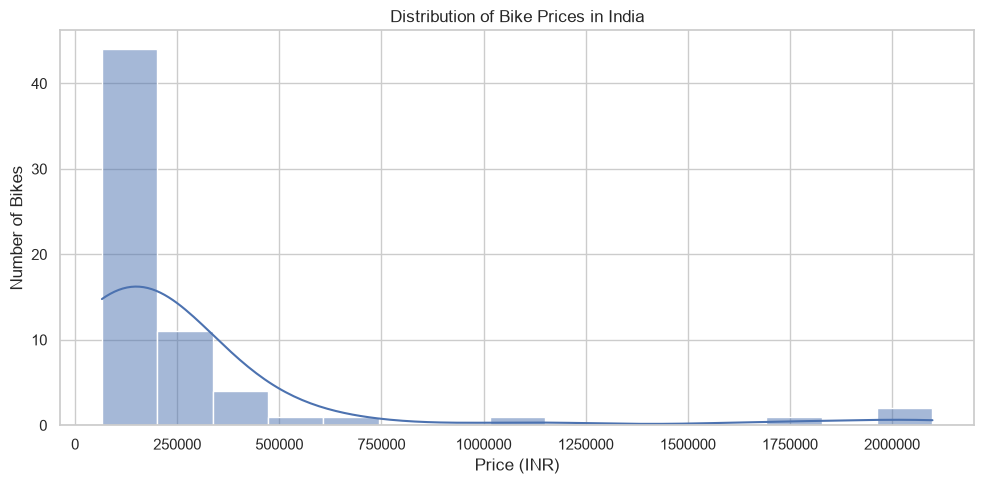

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Distribution of prices
plt.figure(figsize=(10, 5))
sns.histplot(data=clean_df, x="Price_INR", bins=15, kde=True)

plt.title("Distribution of Bike Prices in India")
plt.xlabel("Price (INR)")
plt.ylabel("Number of Bikes")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

### Step 20 — Bike price comparison

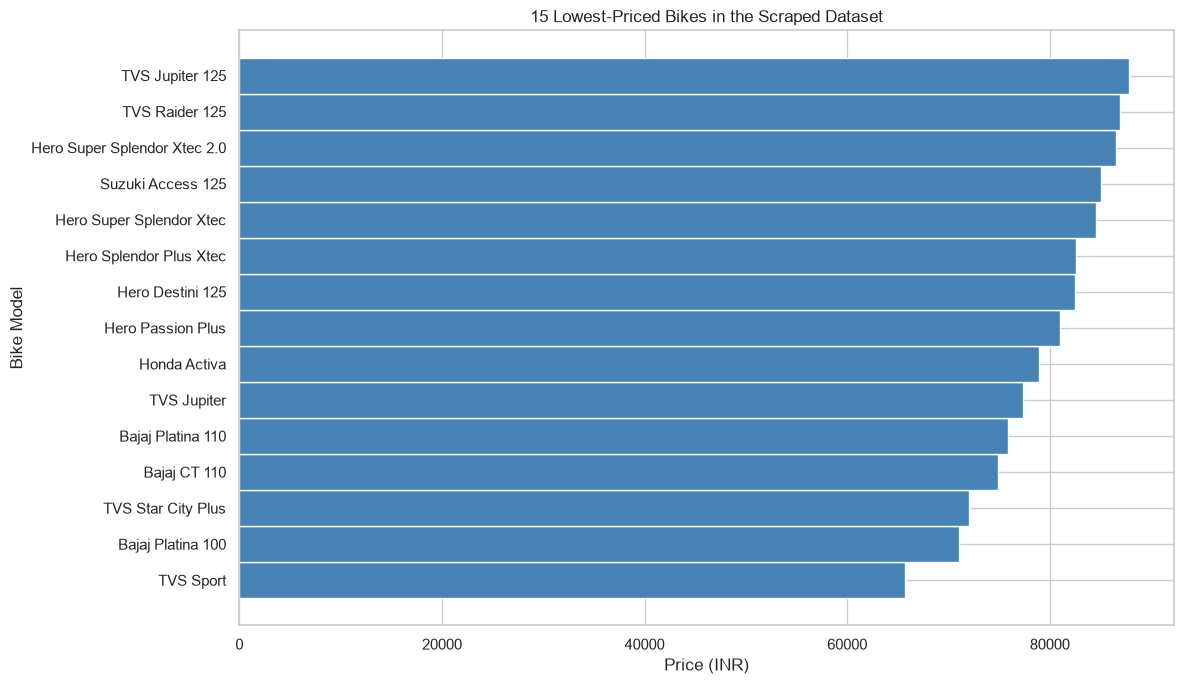

In [26]:
price_sample = (
    clean_df.sort_values("Price_INR")
    .head(15)
    .sort_values("Price_INR")
)

plt.figure(figsize=(12, 7))

plt.barh(
    price_sample["Bike_Name"],
    price_sample["Price_INR"],
    height=1.0,
    color="steelblue"
)

plt.title("15 Lowest-Priced Bikes in the Scraped Dataset")
plt.xlabel("Price (INR)")
plt.ylabel("Bike Model")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

### Step 21 — Brand-wise bike counts

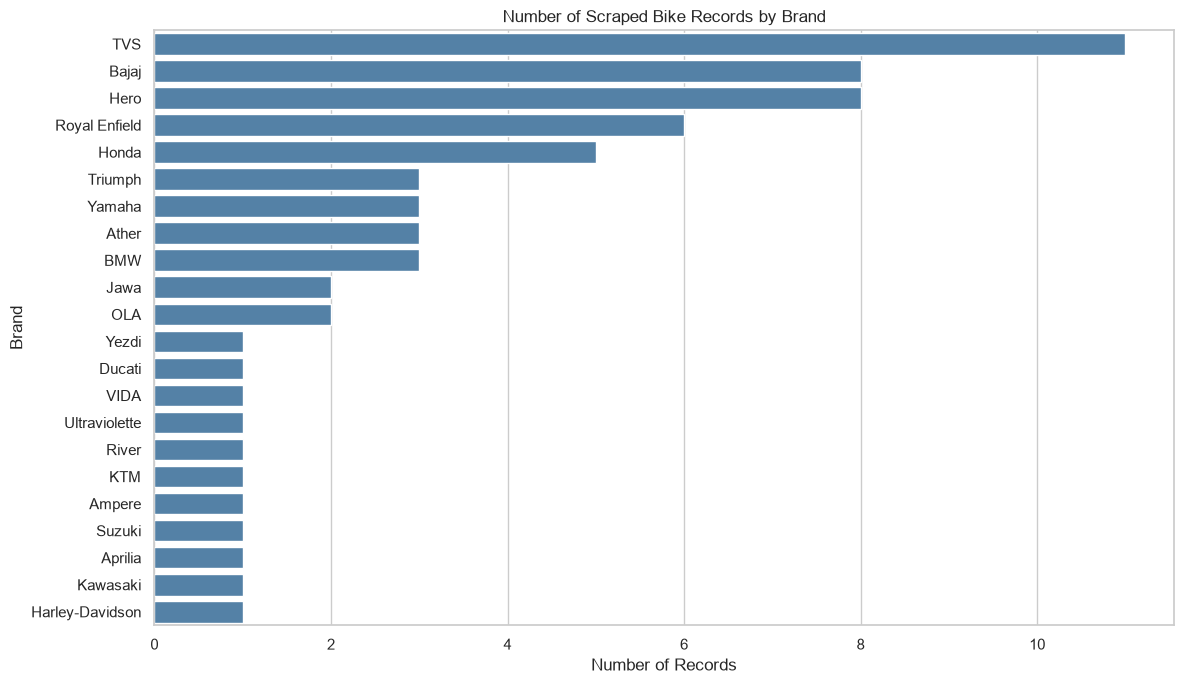

In [21]:
brand_counts = clean_df["Brand"].value_counts().reset_index()
brand_counts.columns = ["Brand", "Model_Count"]

plt.figure(figsize=(12, 7))
sns.barplot(
    data=brand_counts,
    x="Model_Count",
    y="Brand",
    color="steelblue",
    errorbar=None
)

plt.title("Number of Scraped Bike Records by Brand")
plt.xlabel("Number of Records")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

## Step 22 — Bivariate analysis: Price vs Engine Capacity

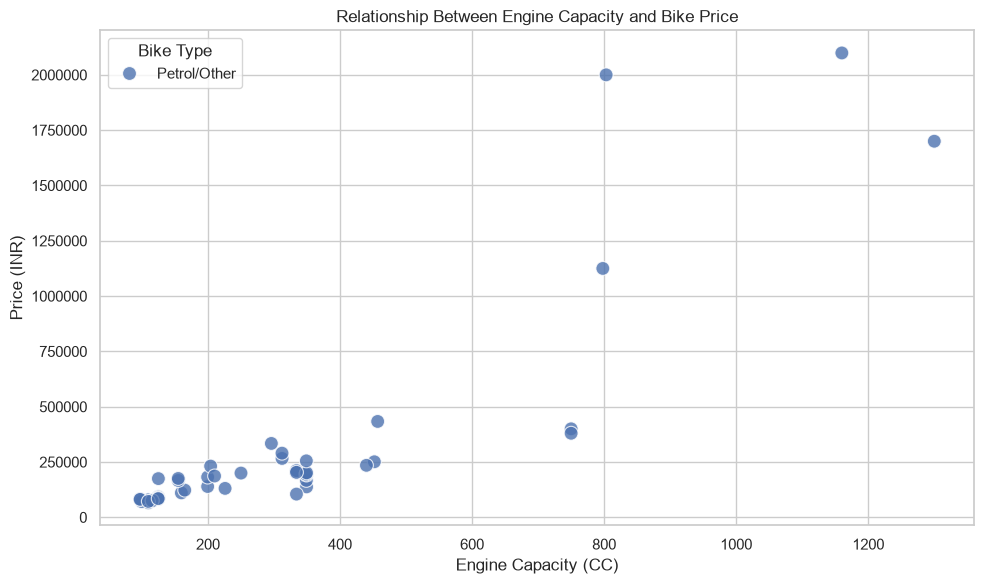

Records plotted: 51
Pearson correlation: 0.869


In [27]:
# Step 22: Price vs Engine Capacity

plot_df = clean_df.dropna(
    subset=["Price_INR", "Engine_CC"]
).copy()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_df,
    x="Engine_CC",
    y="Price_INR",
    hue="Bike_Type",
    s=100,
    alpha=0.8
)

plt.title("Relationship Between Engine Capacity and Bike Price")
plt.xlabel("Engine Capacity (CC)")
plt.ylabel("Price (INR)")
plt.ticklabel_format(style="plain", axis="y")
plt.legend(title="Bike Type")
plt.tight_layout()
plt.show()

# Calculate correlation for records with both values available
correlation = plot_df["Engine_CC"].corr(plot_df["Price_INR"])

print("Records plotted:", len(plot_df))
print("Pearson correlation:", round(correlation, 3))

## Step 23 — Bivariate analysis: Price vs Power (BHP)

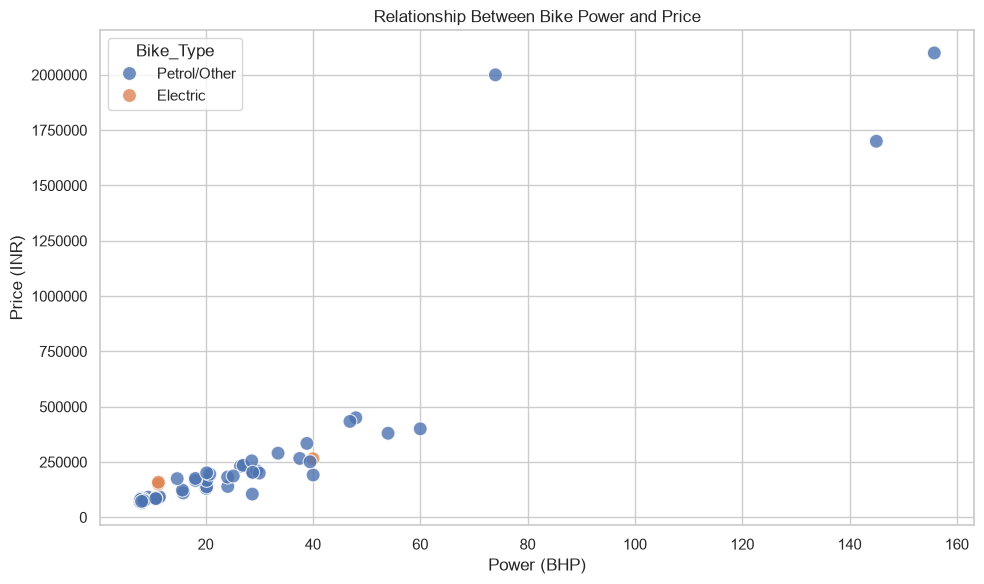

Records plotted: 55
Pearson correlation: 0.901


In [28]:
# Step 23: Relationship between Price and Power

power_df = clean_df.dropna(
    subset=["Price_INR", "Power_BHP"]
).copy()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=power_df,
    x="Power_BHP",
    y="Price_INR",
    hue="Bike_Type",
    s=100,
    alpha=0.8
)

plt.title("Relationship Between Bike Power and Price")
plt.xlabel("Power (BHP)")
plt.ylabel("Price (INR)")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

correlation = power_df["Power_BHP"].corr(
    power_df["Price_INR"]
)

print("Records plotted:", len(power_df))
print("Pearson correlation:", round(correlation, 3))

## Step 24 — Mileage vs Price

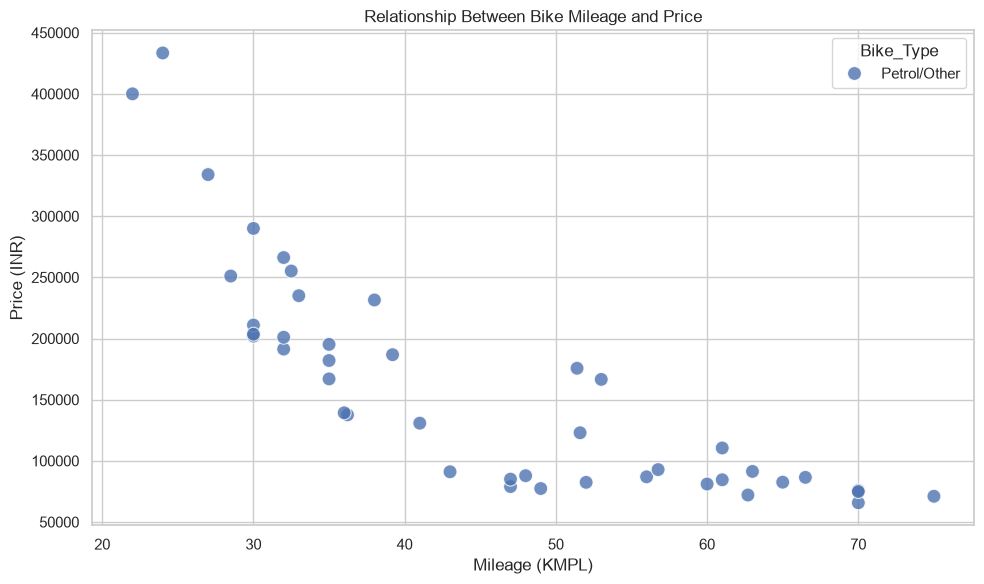

Records plotted: 43
Pearson correlation: -0.815


In [29]:
# Step 24: Relationship between Mileage and Price

mileage_df = clean_df.dropna(
    subset=["Mileage_KMPL", "Price_INR"]
).copy()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=mileage_df,
    x="Mileage_KMPL",
    y="Price_INR",
    hue="Bike_Type",
    s=100,
    alpha=0.8
)

plt.title("Relationship Between Bike Mileage and Price")
plt.xlabel("Mileage (KMPL)")
plt.ylabel("Price (INR)")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

correlation = mileage_df["Mileage_KMPL"].corr(
    mileage_df["Price_INR"]
)

print("Records plotted:", len(mileage_df))
print("Pearson correlation:", round(correlation, 3))

## Step 25 — Correlation heatmap

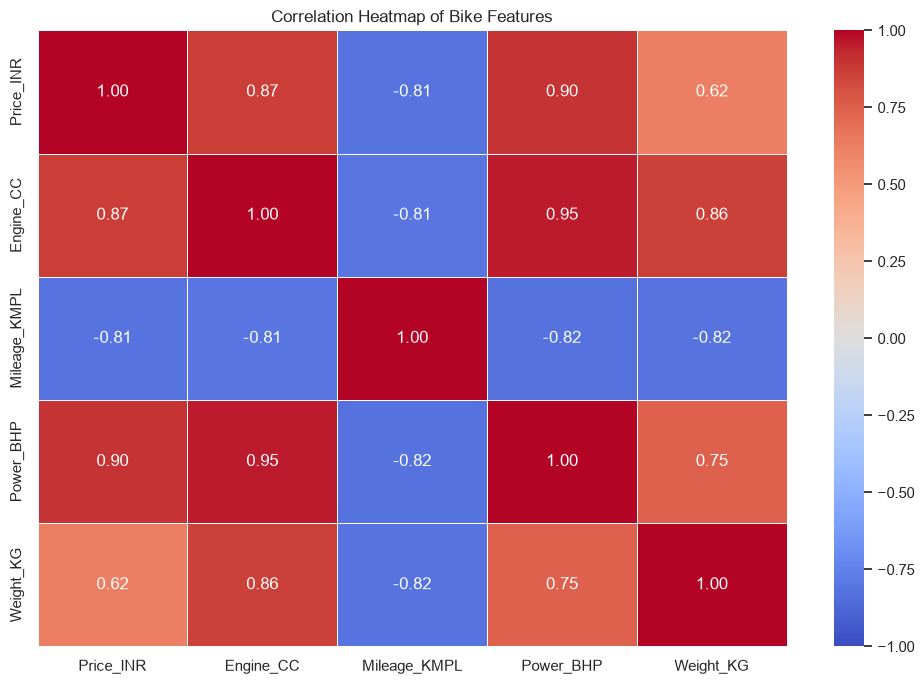

,Price_INR,Engine_CC,Mileage_KMPL,Power_BHP,Weight_KG
Price_INR,1.000,0.869,-0.815,0.901,0.623
Engine_CC,0.869,1.000,-0.809,0.953,0.864
Mileage_KMPL,-0.815,-0.809,1.000,-0.825,-0.820
Power_BHP,0.901,0.953,-0.825,1.000,0.747
Weight_KG,0.623,0.864,-0.820,0.747,1.000


In [30]:
# Step 25: Correlation heatmap

numeric_cols = [
    "Price_INR",
    "Engine_CC",
    "Mileage_KMPL",
    "Power_BHP",
    "Weight_KG"
]

corr_df = clean_df[numeric_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_df,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Bike Features")
plt.tight_layout()
plt.show()

display(corr_df.round(3))

## Step 26 — Detect outliers using boxplots

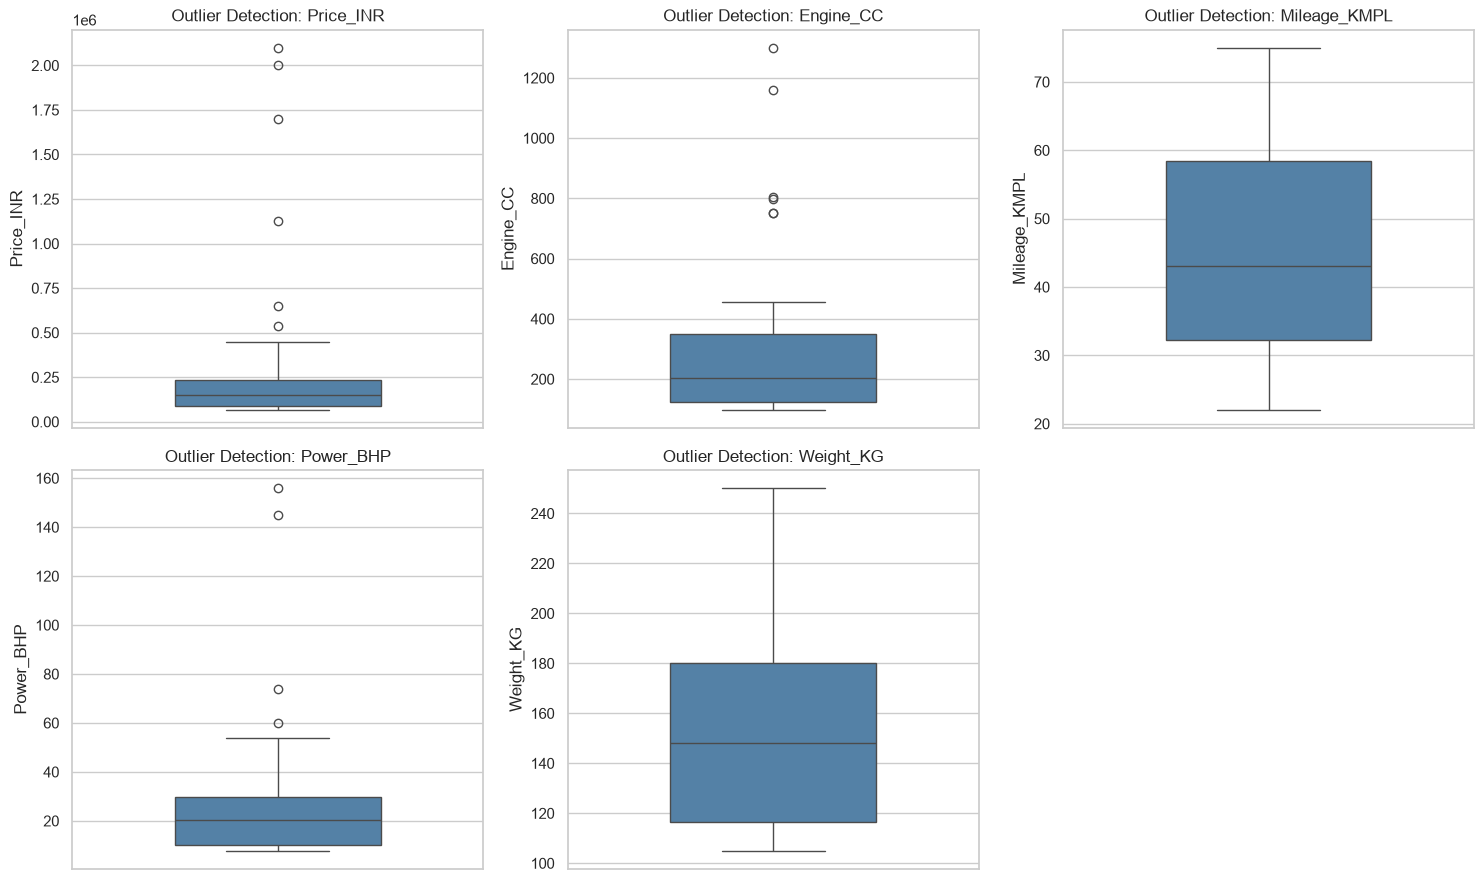

In [31]:
# Step 26: Boxplots for numerical features

numeric_cols = [
    "Price_INR",
    "Engine_CC",
    "Mileage_KMPL",
    "Power_BHP",
    "Weight_KG"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(
        y=clean_df[col].dropna(),
        ax=axes[i],
        color="steelblue",
        width=0.5
    )
    axes[i].set_title(f"Outlier Detection: {col}")
    axes[i].set_ylabel(col)

# Hide the unused sixth subplot
axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

## Step 27 — Calculate outlier counts using IQR

In [32]:
# Step 27: IQR-based outlier detection

outlier_results = []

for col in numeric_cols:
    values = clean_df[col].dropna()

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = values[
        (values < lower_bound) | (values > upper_bound)
    ]

    outlier_results.append({
        "Feature": col,
        "Lower_Bound": round(lower_bound, 2),
        "Upper_Bound": round(upper_bound, 2),
        "Outlier_Count": len(outliers)
    })

outlier_df = pd.DataFrame(outlier_results)
display(outlier_df)

,Feature,Lower_Bound,Upper_Bound,Outlier_Count
0,Price_INR,-124860.00,450916.00,6
1,Engine_CC,-211.75,685.45,6
2,Mileage_KMPL,-6.94,97.57,0
3,Power_BHP,-19.01,59.01,4
4,Weight_KG,21.25,275.25,0


## Step 28 — Create a pivot table

In [33]:
# Step 28: Pivot table by bike type

pivot_table = pd.pivot_table(
    clean_df,
    index="Bike_Type",
    values=[
        "Price_INR",
        "Engine_CC",
        "Mileage_KMPL",
        "Power_BHP",
        "Weight_KG"
    ],
    aggfunc="mean"
).round(2)

print("Average specifications by bike type:")
display(pivot_table)

Average specifications by bike type:


,Engine_CC,Mileage_KMPL,Power_BHP,Price_INR,Weight_KG
Bike_Type,,,,,
Electric,NaN,NaN,18.05,131046.73,NaN
Petrol/Other,301.9,45.52,27.84,302068.74,150.0


## Step 29 — Visualize average price by bike type

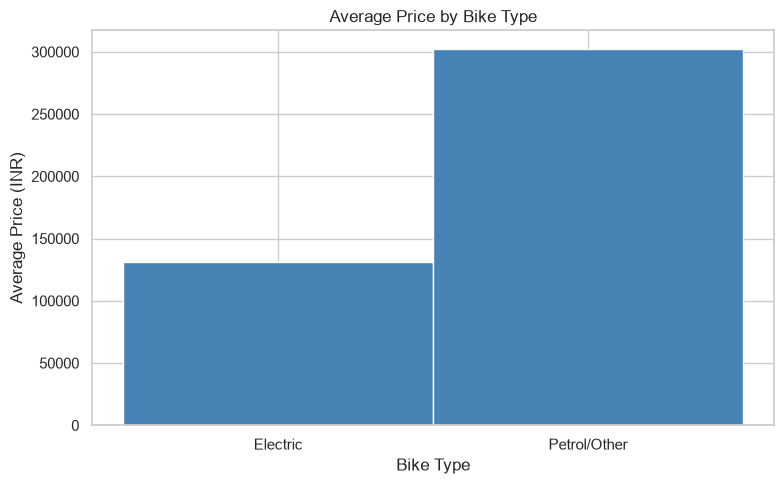

,Bike_Type,Price_INR
0,Electric,131046.73
1,Petrol/Other,302068.74


In [34]:
# Step 29: Average price by bike type

avg_price = (
    clean_df.groupby("Bike_Type", as_index=False)["Price_INR"]
    .mean()
)

plt.figure(figsize=(8, 5))

plt.bar(
    avg_price["Bike_Type"],
    avg_price["Price_INR"],
    color="steelblue",
    width=1.0
)

plt.title("Average Price by Bike Type")
plt.xlabel("Bike Type")
plt.ylabel("Average Price (INR)")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

display(avg_price.round(2))

## Step 30 — Create a clean final insights table

In [35]:
# Step 30: Final EDA summary

print("BIKEWALE EDA — KEY STATISTICS")
print("=" * 45)

print("Total scraped records:", len(clean_df))
print("Unique brands:", clean_df["Brand"].nunique())
print("Electric records:", (clean_df["Bike_Type"] == "Electric").sum())
print("Petrol/Other records:", (clean_df["Bike_Type"] == "Petrol/Other").sum())

print("\nPrice statistics:")
print("Minimum price: ₹{:,.0f}".format(clean_df["Price_INR"].min()))
print("Median price: ₹{:,.0f}".format(clean_df["Price_INR"].median()))
print("Maximum price: ₹{:,.0f}".format(clean_df["Price_INR"].max()))

print("\nMissing values:")
display(clean_df.isnull().sum().to_frame("Missing_Count"))

print("\nAverage price by bike type:")
display(
    clean_df.groupby("Bike_Type")["Price_INR"]
    .agg(["count", "mean", "median"])
    .round(2)
)

BIKEWALE EDA — KEY STATISTICS
Total scraped records: 65
Unique brands: 22
Electric records: 11
Petrol/Other records: 54

Price statistics:
Minimum price: ₹65,721
Median price: ₹150,498
Maximum price: ₹2,099,000

Missing values:


,Missing_Count
Bike_Name,0
Price_INR,0
Engine_CC,14
Mileage_KMPL,22
Power_BHP,10
Weight_KG,22
Description,0
URL,0
Has_Product_JSONLD,0
HTTP_Status,0



Average price by bike type:


,count,mean,median
Bike_Type,,,
Electric,11,131046.73,119444.0
Petrol/Other,54,302068.74,175346.0


## Step 31 — Save the final dataset and analysis outputs

In [36]:
# Step 31: Export final dataset and key tables

clean_df.to_csv("bikewale_cleaned_dataset.csv", index=False)
pivot_table.to_csv("bikewale_pivot_table.csv")
outlier_df.to_csv("bikewale_outlier_analysis.csv", index=False)
corr_df.to_csv("bikewale_correlation_matrix.csv")

print("Export completed:")
print("1. bikewale_cleaned_dataset.csv")
print("2. bikewale_pivot_table.csv")
print("3. bikewale_outlier_analysis.csv")
print("4. bikewale_correlation_matrix.csv")

Export completed:
1. bikewale_cleaned_dataset.csv
2. bikewale_pivot_table.csv
3. bikewale_outlier_analysis.csv
4. bikewale_correlation_matrix.csv


# Step 32 — Final EDA insights and conclusion

# BikeWale Web Scraping and Exploratory Data Analysis

## Key Findings

1. **Dataset composition:** The cleaned dataset contains 65 records from 22 brands, including 11 electric bikes and 54 petrol/other bikes.
2. **Price distribution:** Prices range from ₹65,721 to ₹20,99,000, with a median of ₹1,50,498. The distribution is right-skewed because a small number of premium bikes have much higher prices.
3. **Brand representation:** TVS has the largest number of records in the scraped sample, followed by Bajaj and Hero.
4. **Price and power:** Pearson correlation is approximately +0.901, indicating a strong positive linear association among the 55 records with both values available.
5. **Price and mileage:** Pearson correlation is approximately −0.815 among the 43 records with both values available. Higher reported mileage tends to coincide with lower prices in this sample.
6. **Outlier analysis:** The IQR method flagged 6 price values, 6 engine-capacity values, and 4 power values. These require validation rather than automatic removal.
7. **Data quality:** Engine capacity, mileage, power, and weight contain missing values. Some scraped specifications require verification before drawing definitive conclusions.

## Conclusion

This project demonstrates how web scraping and exploratory data analysis can be used to collect, clean, summarize, and visualize motorcycle information from BikeWale. Histograms, bar charts, scatter plots, a correlation heatmap, boxplots, and a pivot table helped reveal patterns in pricing and specifications.

The results suggest that power and engine capacity are positively associated with price, while mileage is negatively associated with price in the current sample. However, brand, vehicle category, features, and data quality may influence these relationships.

The dataset is a useful starting point for comparing bikes, but it is not sufficient to declare one model the best in India. Future improvements should include verifying specifications against source pages, collecting more complete records, adding electric-bike range and charging information, and defining a ranking method based on user needs and weighted criteria.

## Challenges

- Extracting structured information from dynamically structured web pages.
- Handling missing or incorrectly extracted specifications.
- Distinguishing individual bike pages from comparison pages.
- Detecting potential outliers without removing valid premium models.
- Ensuring that the scraped sample accurately represents the intended market.

## Future Improvements

- Validate each model name, price, and specification against its source page.
- Increase the number of verified bike records.
- Add features such as fuel type, range, safety features, and maintenance costs.
- Build a transparent multi-criteria ranking system for different rider budgets and preferences.
- Repeat data collection periodically to account for changing prices and new models.


Columns: ['Bike_Name', 'Price_INR', 'Engine_CC', 'Mileage_KMPL', 'Power_BHP', 'Weight_KG', 'Description', 'URL', 'Has_Product_JSONLD', 'HTTP_Status', 'Review_Flag', 'Brand', 'Bike_Type', 'Verification_Status']
Valid engine capacity records: 51
Valid mileage records: 43


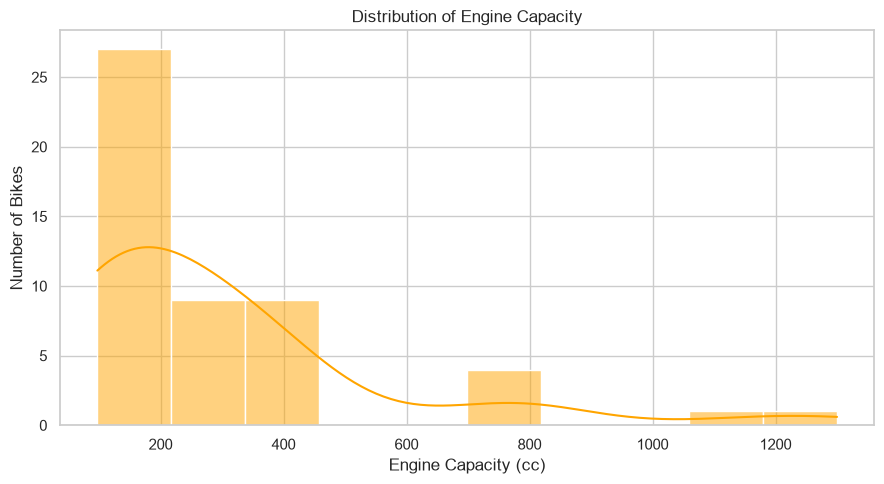

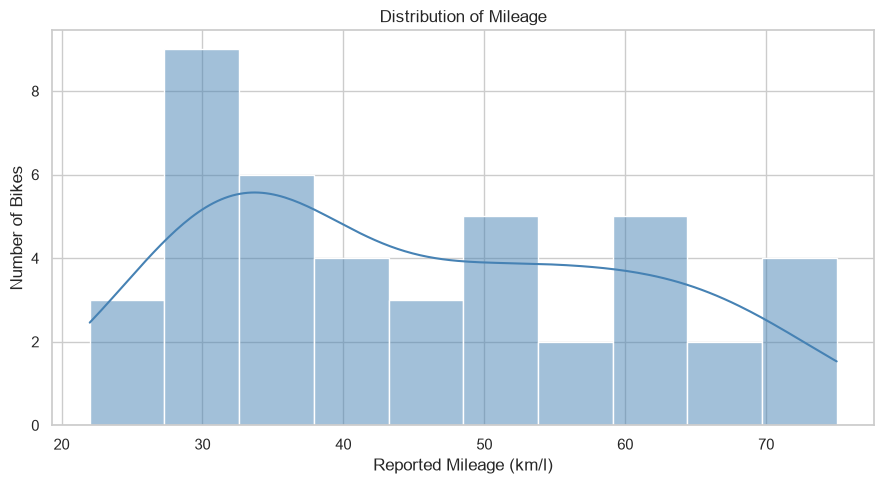

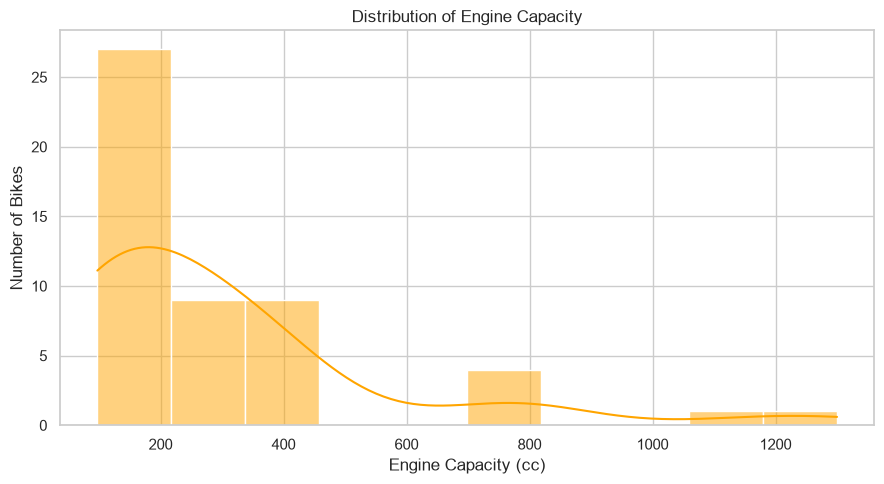

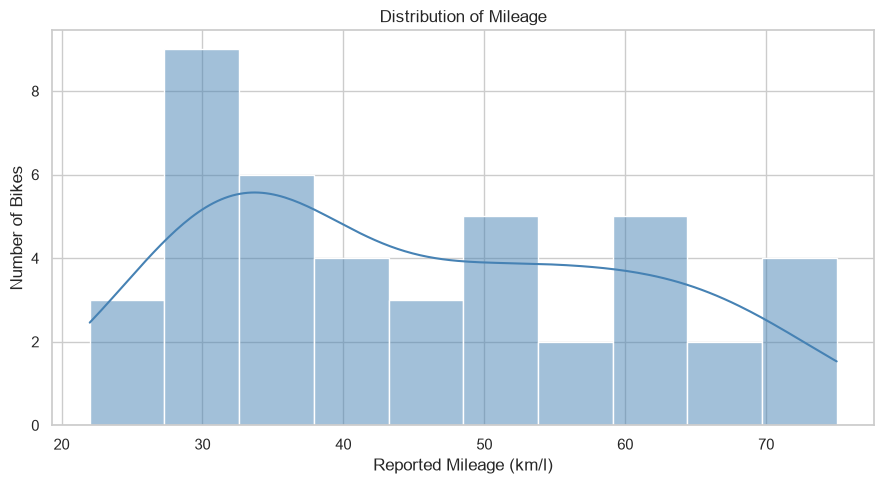

In [38]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the cleaned dataset
df = pd.read_csv("bikewale_cleaned_dataset.csv")

# Check the actual column names
print("Columns:", df.columns.tolist())

# 2. Convert relevant columns to numeric
df["Engine_CC"] = pd.to_numeric(df["Engine_CC"], errors="coerce")
df["Mileage_KMPL"] = pd.to_numeric(df["Mileage_KMPL"], errors="coerce")

# 3. Exclude electric bikes, if the dataset has a bike-type column
if "Bike_Type" in df.columns:
    petrol_df = df[
        df["Bike_Type"].astype(str).str.lower() != "electric"
    ].copy()
else:
    # If no bike-type column exists, use available records.
    # Check electric-bike records manually before interpreting results.
    petrol_df = df.copy()

# 4. Prepare valid values
engine_data = petrol_df["Engine_CC"].dropna()
mileage_data = petrol_df["Mileage_KMPL"].dropna()

print("Valid engine capacity records:", len(engine_data))
print("Valid mileage records:", len(mileage_data))

# 5. Visual 1: Engine Capacity Distribution
plt.figure(figsize=(9, 5))
sns.histplot(engine_data, bins=10, kde=True, color="orange")

plt.title("Distribution of Engine Capacity")
plt.xlabel("Engine Capacity (cc)")
plt.ylabel("Number of Bikes")
plt.tight_layout()
plt.show()

# 6. Visual 2: Mileage Distribution
plt.figure(figsize=(9, 5))
sns.histplot(mileage_data, bins=10, kde=True, color="steelblue")

plt.title("Distribution of Mileage")
plt.xlabel("Reported Mileage (km/l)")
plt.ylabel("Number of Bikes")
plt.tight_layout()
plt.show()

# 7. Optional: Save both charts for your PPT
plt.figure(figsize=(9, 5))
sns.histplot(engine_data, bins=10, kde=True, color="orange")
plt.title("Distribution of Engine Capacity")
plt.xlabel("Engine Capacity (cc)")
plt.ylabel("Number of Bikes")
plt.tight_layout()
plt.savefig("slide9_engine_capacity_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(9, 5))
sns.histplot(mileage_data, bins=10, kde=True, color="steelblue")
plt.title("Distribution of Mileage")
plt.xlabel("Reported Mileage (km/l)")
plt.ylabel("Number of Bikes")
plt.tight_layout()
plt.savefig("slide9_mileage_histogram.png", dpi=300, bbox_inches="tight")
plt.show()
